In [1]:
import os
import sys

# Get the absolute path to the parent directory
project_root = os.path.abspath("..")

# Add the project root to Python's module search path
sys.path.append(project_root)


In [2]:
from typing_extensions import Literal
from langchain_core.messages import HumanMessage,AIMessage,get_buffer_string
from langgraph.graph import StateGraph, START , END
from langgraph.types import Command

In [3]:
from deep_research.prompt import transform_messages_into_research_topic_prompt, clarify_with_user_instructions
from deep_research.state import AgentInputState,AgentState,ClarifyWithUser,ResearchQuestion
from deep_research.utils import get_today_str

In [4]:
ClarifyWithUser

deep_research.state.ClarifyWithUser

In [5]:
import getpass
import os
 
if "GOOGLE_API_KEY"not in  os.environ:
    os.environ["GOOGLE_API_KEY"]=getpass.getpass("Enter your Google AI API Key: ")

In [6]:
from langchain_google_genai import ChatGoogleGenerativeAI

In [7]:
model=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite-lite",
    temperature=1.0,
    max_tokens=None,
    timeout=None

)

In [8]:
def clarify_with_user(state: AgentState) -> Command[Literal["write_research_brief", "__end__"]]:
    """
    Determine if the user's request contains sufficient information to proceed with research.
    
    Uses structured output to make deterministic decisions and avoid hallucination.
    Routes to either research brief generation or ends with a clarification question.
    """
    # Set up structured output model
    structured_output_model = model.with_structured_output(ClarifyWithUser)

    # Invoke the model with clarification instructions
    response = structured_output_model.invoke([
        HumanMessage(content=clarify_with_user_instructions.format(
            messages=get_buffer_string(messages=state["messages"]), 
            date=get_today_str()
        ))
    ])
    
    # Route based on clarification need
    if response.need_clarification:
        return Command(
            goto=END, 
            update={"messages": [AIMessage(content=response.question)]}
        )
    else:
        return Command(
            goto="write_research_brief", 
            update={"messages": [AIMessage(content=response.verification)]}
        )

In [9]:
def write_research_brief(state: AgentState):
    """
    Transform the conversation history into a comprehensive research brief.
    
    Uses structured output to ensure the brief follows the required format
    and contains all necessary details for effective research.
    """
    # Set up structured output model
    structured_output_model = model.with_structured_output(ResearchQuestion)
    
    # Generate research brief from conversation history
    response = structured_output_model.invoke([
        HumanMessage(content=transform_messages_into_research_topic_prompt.format(
            messages=get_buffer_string(state.get("messages", [])),
            date=get_today_str()
        ))
    ])
    
    # Update state with generated research brief and pass it to the supervisor
    return {
        "research_brief": response.research_brief,
        "supervisor_messages": [HumanMessage(content=f"{response.research_brief}.")]
    }

In [10]:
# ===== GRAPH CONSTRUCTION =====

# Build the scoping workflow
deep_researcher_builder = StateGraph(AgentState, input_schema=AgentInputState)

# Add workflow nodes
deep_researcher_builder.add_node("clarify_with_user", clarify_with_user)
deep_researcher_builder.add_node("write_research_brief", write_research_brief)

# Add workflow edges
deep_researcher_builder.add_edge(START, "clarify_with_user")
deep_researcher_builder.add_edge("write_research_brief", END)

# Compile the workflow
scope_research = deep_researcher_builder.compile()

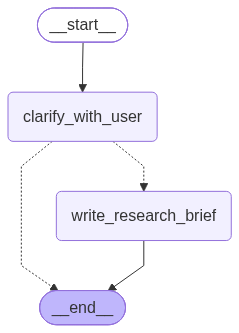

In [11]:
from IPython.display import Image, display
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()
scope = deep_researcher_builder.compile(checkpointer=checkpointer)
display(Image(scope.get_graph(xray=True).draw_mermaid_png()))

In [12]:

from langchain_core.messages import HumanMessage
thread = {"configurable": {"thread_id": "1"}}
result = scope.invoke({"messages": [HumanMessage(content="I want to research the best IPL Team")]}, config=thread)
print(result['messages'])

[HumanMessage(content='I want to research the best IPL Team', additional_kwargs={}, response_metadata={}, id='e3489312-d004-4480-b074-0e8a99931cec'), AIMessage(content='To help me research the "best" IPL (Indian Premier League) team effectively, could you please clarify a few details?\n\n1. **What criteria should define \'best\'?** (e.g., most championship titles, highest overall win-loss ratio, performance in the most recent 2026 season, brand value, or fan following?)\n2. **What is the timeframe for this research?** (e.g., all-time history since the league\'s inception in 2008, or a focus on the last 3-5 years?)\n3. **Are there specific teams or metrics you want me to compare directly?**', additional_kwargs={}, response_metadata={}, id='1c8bce3d-1be9-4c27-80ee-9bff18c555c8', tool_calls=[], invalid_tool_calls=[])]


In [13]:
result = scope.invoke({"messages": [HumanMessage(content="More tropies with overall win percentage")]}, config=thread)
print(result['messages'])

[HumanMessage(content='I want to research the best IPL Team', additional_kwargs={}, response_metadata={}, id='e3489312-d004-4480-b074-0e8a99931cec'), AIMessage(content='To help me research the "best" IPL (Indian Premier League) team effectively, could you please clarify a few details?\n\n1. **What criteria should define \'best\'?** (e.g., most championship titles, highest overall win-loss ratio, performance in the most recent 2026 season, brand value, or fan following?)\n2. **What is the timeframe for this research?** (e.g., all-time history since the league\'s inception in 2008, or a focus on the last 3-5 years?)\n3. **Are there specific teams or metrics you want me to compare directly?**', additional_kwargs={}, response_metadata={}, id='1c8bce3d-1be9-4c27-80ee-9bff18c555c8', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='More tropies with overall win percentage', additional_kwargs={}, response_metadata={}, id='f13eb683-cbac-467d-b2e2-09c8d18f9313'), AIMessage(content='T

In [14]:
result["research_brief"]

"I want to determine which Indian Premier League (IPL) team is the all-time 'best' from the league's inception in 2008 through the 2026 season, specifically evaluating them based on a combination of championship trophies won and overall win percentage. Since I have not specified how to weigh these two metrics, please analyze the data under different scenarios (e.g., prioritizing trophy count versus prioritizing overall win consistency) to identify the top team. Please gather up-to-date and accurate statistics directly from official sources like the official IPL website (iplt20.com), official team sites, and highly reputable cricket databases such as ESPNcricinfo."